# Pulse broadening and the bit-rate limit

Notebook 117 gave the dispersion of fibres as numbers: D in ps/(nm km),
$\beta_2$ in ps²/km, intermodal delays in ps/km. Here they act on pulses. A
digital link sends one pulse per bit; when the pulses spread into their
neighbours' time slots, ones and zeros can no longer be told apart. How far
a link reaches at a given bit rate therefore depends on the dispersion, on
the pulse and on the source:

1. a Gaussian pulse in a single-mode fibre: the dispersion length,
2. chirped pulses, which can first get shorter,
3. third-order dispersion at the zero-dispersion wavelength,
4. the spectral width of the source: lasers against LEDs,
5. the impulse response of multimode fibres,
6. the map of bit rate against distance that summarizes the series so far.

Pulses propagate with `fibrecomm.propagate()`, which multiplies the
spectrum of the field envelope by
$\exp(i\beta_2\Omega^2L/2 + i\beta_3\Omega^3L/6 - \alpha L/2)$ (fields
$\exp(i(\beta z - \omega t))$, Agrawal's convention). Time in ps, length in km.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import fibres, fibrecomm as fc, ultrafast, sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(118)

smf = fibres.smf28()
D1550 = float(fibres.dispersion(smf, 1.55))
beta2 = fibres.beta2_from_D(D1550, 1550)
l0 = brentq(lambda w: fibres.dispersion(smf, w), 1.25, 1.40)
S0 = float(fibres.dispersion_slope(smf, l0))
c_nm_ps = 2.99792458E5
beta3 = (l0*1E3)**4*S0/(4*np.pi**2*c_nm_ps**2)
print("SMF model: D = {:.2f} ps/(nm km), beta2 = {:.2f} ps²/km at 1550 nm".format(D1550, beta2))
print("           zero at {:.1f} nm, S0 = {:.4f} ps/(nm² km), beta3 = {:.4f} ps³/km there".format(l0*1E3, S0, beta3))

SMF model: D = 17.63 ps/(nm km), beta2 = -22.48 ps²/km at 1550 nm
           zero at 1300.8 nm, S0 = 0.0883 ps/(nm² km), beta3 = 0.0713 ps³/km there


## 1. A Gaussian pulse in a single-mode fibre

An unchirped Gaussian pulse $A = \exp(-t^2/(2T_0^2))$ ($T_0$ is the 1/e half
width of the power, the FWHM is $1.665\,T_0$) has the spectral width
$1/T_0$. After the length $z$ it is still Gaussian, with the width

$$
T_1 = T_0\sqrt{1 + (z/L_D)^2}, \qquad L_D = \frac{T_0^2}{|\beta_2|},
$$

the **dispersion length**. The pulse also becomes chirped: in the standard
fibre at 1550 nm ($\beta_2 < 0$) the blue components arrive first. Short
pulses suffer most: $L_D$ falls with the square of the width. A 10 Gb/s
pulse ($T_0 \approx 30$ ps) has $L_D \approx 40$ km, a 40 Gb/s pulse 2.5 km.

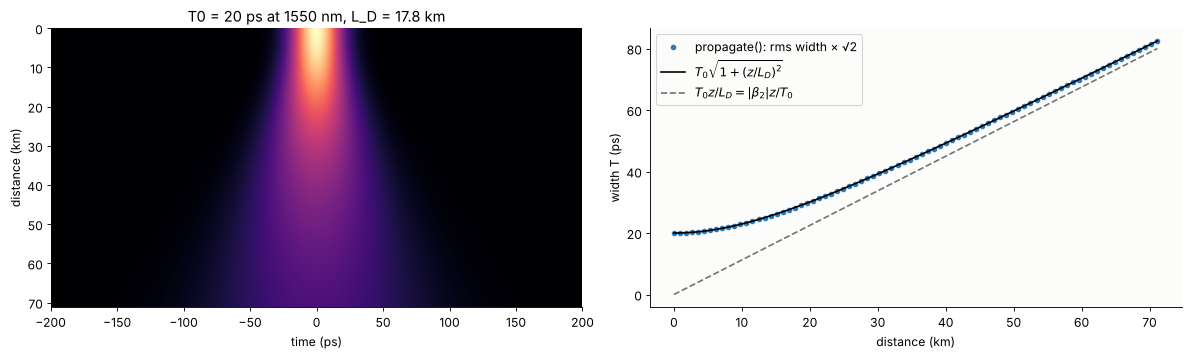

after L_D: FWHM 47.10 ps from fibrecomm, 47.10 ps from ultrafast.gaussian_broadening()


In [2]:
t = np.linspace(-400, 400, 4096, endpoint=False)
T0 = 20.0
L_D = T0**2/abs(beta2)
zs = np.linspace(0, 4*L_D, 81)
A0 = fc.gaussian_pulse(t, T0)
P = np.array([np.abs(fc.propagate(t, A0, z, beta2))**2 for z in zs])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].imshow(P, extent=[t[0], t[-1], zs[-1], zs[0]], aspect="auto", cmap="magma")
axes[0].set_xlim(-200, 200)
axes[0].set_xlabel("time (ps)"); axes[0].set_ylabel("distance (km)")
axes[0].set_title(f"T0 = {T0:.0f} ps at 1550 nm, L_D = {L_D:.1f} km")
widths = np.sqrt(2*np.sum(P*t**2, axis=1)/np.sum(P, axis=1))
axes[1].plot(zs, widths, "o", ms=4, color=BLUE, label="propagate(): rms width × √2")
axes[1].plot(zs, fc.gaussian_width(zs, T0, beta2), color="k", label=r"$T_0\sqrt{1 + (z/L_D)^2}$")
axes[1].plot(zs, T0*zs/L_D, color=GREY, ls="--", label=r"$T_0 z/L_D = |\beta_2|z/T_0$")
axes[1].set_xlabel("distance (km)"); axes[1].set_ylabel("width T (ps)"); axes[1].legend()
plt.tight_layout()
plt.show()

gdd_fs2 = beta2*L_D*1E6             # 1 ps² = 1e6 fs²
print("after L_D: FWHM {:.2f} ps from fibrecomm, {:.2f} ps from ultrafast.gaussian_broadening()".format(
      1.6651*fc.gaussian_width(L_D, T0, beta2), ultrafast.gaussian_broadening(1.6651*T0*1E3, gdd_fs2)*1E-3))

The width grows quadratically at first and linearly beyond $L_D$, where the
pulse has become a "map" of its spectrum: each frequency arrives at its own
time $\beta_2\Omega z$. The same broadening in the femtosecond world of
notebook 81 (`ultrafast.gaussian_broadening()`, GDD in fs²) gives the same
number: kilometres and picoseconds are millimetres and femtoseconds scaled
by $10^6$ in GDD.

## 2. Chirped pulses

A pulse with a linear chirp, $A = \exp(-(1 + iC)t^2/(2T_0^2))$, has a wider
spectrum than its width requires. Its width after $z$ is

$$
\frac{T_1}{T_0} = \sqrt{\left(1 + \frac{C\beta_2z}{T_0^2}\right)^2 + \left(\frac{\beta_2z}{T_0^2}\right)^2}.
$$

If $C\beta_2 < 0$ the dispersion first undoes the chirp: the pulse gets
shorter, reaches its transform limit, and only then spreads, faster than an
unchirped pulse would. Directly modulated semiconductor lasers chirp with
$C \approx -4$ to $-6$ (the linewidth enhancement factor); with
$\beta_2 < 0$ at 1550 nm that is the wrong sign, which is why 1550 nm links
beyond a few tens of kilometres use external modulators.

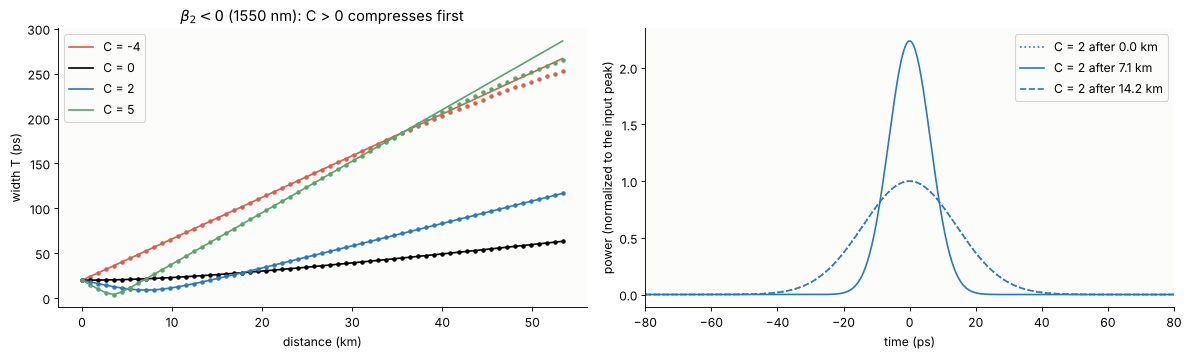

C = 2: shortest pulse T0/sqrt(1 + C²) = 8.9 ps after C T0²/(|β2|(1 + C²)) = 7.1 km


In [3]:
zs = np.linspace(0, 3*L_D, 61)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for C, c in ((-4, RED), (0, "k"), (2, BLUE), (5, GREEN)):
    A0 = fc.gaussian_pulse(t, T0, C)
    num = []
    for z in zs:
        Pz = np.abs(fc.propagate(t, A0, z, beta2))**2
        num.append(np.sqrt(2*np.sum(Pz*t**2)/np.sum(Pz)))
    axes[0].plot(zs, num, "o", ms=3, color=c)
    axes[0].plot(zs, fc.gaussian_width(zs, T0, beta2, C), color=c, label=f"C = {C}")
    if C == 2:
        z_min = C*T0**2/(abs(beta2)*(1 + C**2))
        for z, ls in ((0, ":"), (z_min, "-"), (2*z_min, "--")):
            axes[1].plot(t, np.abs(fc.propagate(t, A0, z, beta2))**2, color=c, ls=ls,
                         label=f"C = 2 after {z:.1f} km")
axes[0].set_xlabel("distance (km)"); axes[0].set_ylabel("width T (ps)"); axes[0].legend()
axes[0].set_title(r"$\beta_2 < 0$ (1550 nm): C > 0 compresses first")
axes[1].set_xlim(-80, 80); axes[1].set_xlabel("time (ps)"); axes[1].set_ylabel("power (normalized to the input peak)")
axes[1].legend()
plt.tight_layout()
plt.show()
print("C = 2: shortest pulse T0/sqrt(1 + C²) = {:.1f} ps after C T0²/(|β2|(1 + C²)) = {:.1f} km".format(
      T0/np.sqrt(5), 2*T0**2/(abs(beta2)*5)))

## 3. Third-order dispersion at the zero-dispersion wavelength

At the zero-dispersion wavelength $\beta_2 = 0$, but D still changes with
the wavelength: $\beta_3 = \lambda^4S_0/(4\pi^2c^2)$, 0.071 ps³/km for the
standard fibre. Third-order dispersion delays the two sides of the spectrum
in the same direction, so the pulse becomes asymmetric with an oscillating
tail (an Airy function). Its effect scales with $T_0^3/\beta_3$ instead of
$T_0^2/|\beta_2|$, so it matters only for short pulses or long distances.
"Zero dispersion" is not zero.

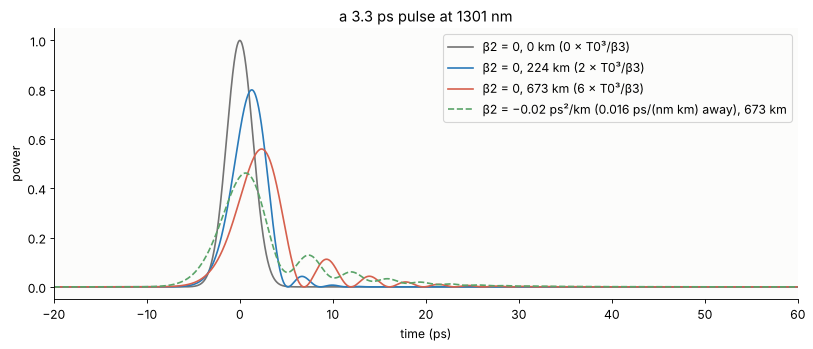

In [4]:
T0s = 2.0
ts = np.linspace(-60, 120, 8192, endpoint=False)
A0 = fc.gaussian_pulse(ts, T0s)
L3 = T0s**3/beta3
fig, ax = plt.subplots(figsize=(12, 4.4))
for L, c in ((0, GREY), (2*L3, BLUE), (6*L3, RED)):
    ax.plot(ts, np.abs(fc.propagate(ts, A0, L, 0.0, beta3))**2, color=c,
            label=f"β2 = 0, {L:.0f} km ({L/L3:.0f} × T0³/β3)")
ax.plot(ts, np.abs(fc.propagate(ts, A0, 6*L3, -0.02, beta3))**2, color=GREEN, ls="--",
        label=f"β2 = −0.02 ps²/km (0.016 ps/(nm km) away), {6*L3:.0f} km")
ax.set_xlim(-20, 60); ax.set_xlabel("time (ps)"); ax.set_ylabel("power")
ax.set_title(f"a {1.665*T0s:.1f} ps pulse at {l0*1E3:.0f} nm"); ax.legend()
plt.show()

## 4. The spectral width of the source

So far the pulses were transform limited: their spectrum came only from
their shape. Real sources add their own spectral width $\sigma_\omega$: an LED
emits 30 to 60 nm, a Fabry–Perot laser several longitudinal modes over a few
nm, a DFB laser one line of a few MHz. For a Gaussian pulse from a source
with a Gaussian spectrum, the rms width grows as (Agrawal, eq. 2.4.23)

$$
\frac{\sigma^2}{\sigma_0^2} = \left(1 + \frac{C\beta_2L}{2\sigma_0^2}\right)^2
+ (1 + V_\omega^2)\left(\frac{\beta_2L}{2\sigma_0^2}\right)^2, \qquad V_\omega = 2\sigma_\omega\sigma_0.
$$

For $V_\omega \gg 1$ (a broad source) this is $\sigma \approx |\beta_2|L\sigma_\omega
= |D|L\sigma_\lambda$: every wavelength travels on its own, and the pulse
shape no longer matters. Below, the source is a pulse multiplied by
Gaussian noise of spectral rms width $\sigma_\omega$ (chaotic light, as in
notebook 74), propagated and averaged over 200 realizations.

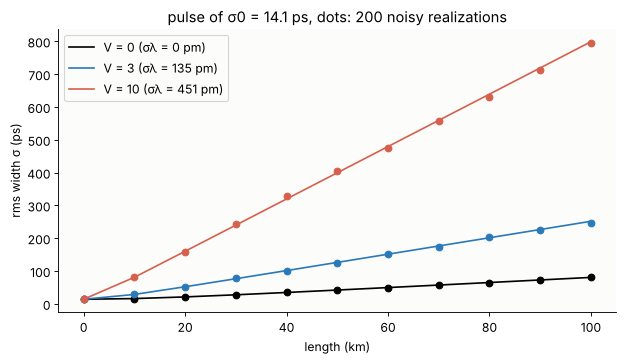

LED, 30 nm                    : σ = |D| L σλ =    5288 ps over 10 km at 1550 nm
Fabry-Perot laser, 2 nm       : σ = |D| L σλ =     353 ps over 10 km at 1550 nm
DFB laser, transform limited  : σ =    16.2 ps over 10 km for σ0 = 14.1 ps


In [5]:
def noisy_source(t, T0, sigma_w, n_real, rng):
    """Realizations of a Gaussian pulse times chaotic light of spectral rms width sigma_w (rad/ps)."""
    dt = t[1] - t[0]
    W = 2*np.pi*np.fft.fftfreq(len(t), dt)
    noise = (rng.standard_normal((n_real, len(t))) + 1j*rng.standard_normal((n_real, len(t))))
    noise = np.fft.fft(np.fft.ifft(noise, axis=1)*np.exp(-W**2/(4*sigma_w**2)), axis=1)
    noise /= np.sqrt(np.mean(np.abs(noise)**2))
    return fc.gaussian_pulse(t, T0)*noise


t = np.linspace(-3000, 3000, 16384, endpoint=False)
T0 = 20.0
sigma0 = T0/np.sqrt(2)
Ls = np.linspace(0, 100, 11)
fig, ax = plt.subplots(figsize=(9, 4.6))
for V, c in ((0.0, "k"), (3.0, BLUE), (10.0, RED)):
    sigma_w = V/(2*sigma0)
    rms = []
    for L in Ls:
        if V == 0:
            Pz = np.abs(fc.propagate(t, fc.gaussian_pulse(t, T0), L, beta2))**2
        else:
            Pz = np.mean(np.abs(np.array([fc.propagate(t, a, L, beta2)
                                          for a in noisy_source(t, T0, sigma_w, 200, rng)]))**2, axis=0)
        mean = np.sum(Pz*t)/np.sum(Pz)
        rms.append(np.sqrt(np.sum(Pz*(t - mean)**2)/np.sum(Pz)))
    theory = sigma0*np.sqrt(1 + (1 + V**2)*(beta2*Ls/(2*sigma0**2))**2)
    sigma_lambda = sigma_w*(1550**2)/(2*np.pi*c_nm_ps)
    ax.plot(Ls, rms, "o", color=c)
    ax.plot(Ls, theory, color=c, label=f"V = {V:.0f} (σλ = {sigma_lambda*1E3:.0f} pm)")
ax.set_xlabel("length (km)"); ax.set_ylabel("rms width σ (ps)")
ax.set_title(f"pulse of σ0 = {sigma0:.1f} ps, dots: 200 noisy realizations"); ax.legend()
plt.show()
for name, sl in (("LED, 30 nm", 30.0), ("Fabry-Perot laser, 2 nm", 2.0), ("DFB laser, transform limited", None)):
    if sl:
        print("{:30s}: σ = |D| L σλ = {:7.0f} ps over 10 km at 1550 nm".format(name, D1550*10*sl))
    else:
        print("{:30s}: σ = {:7.1f} ps over 10 km for σ0 = {:.1f} ps".format(
              name, sigma0*np.sqrt(1 + (beta2*10/(2*sigma0**2))**2), sigma0))

An LED at 1550 nm smears a pulse over 5 ns in 10 km: such links run at
1310 nm (near the zero) or over short multimode fibre. A Fabry–Perot laser
is good for some 500 Mb/s over 10 km at 1550 nm, a DFB laser for 10 Gb/s
over tens of kilometres.

## 5. The impulse response of a multimode fibre

In a multimode fibre each mode group delivers its share of the power at its
own delay (notebooks 115 and 117). With all modes equally excited, the
mode number $m/M$ is uniform and the WKB delays give the impulse response
directly; its Fourier transform is the baseband frequency response, and
the frequency where it has fallen to one half (3 dB optical) is the modal
bandwidth.

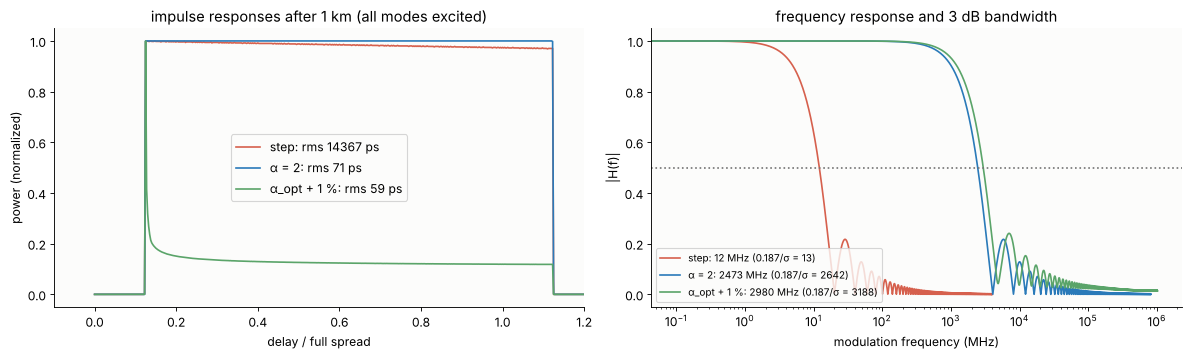

In [6]:
Delta, N1 = 0.01, 1.47
L_km = 1.0
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
u = (np.arange(200_000) + 0.5)/200_000
for name, alpha, c in (("step", 1E6, RED), ("α = 2", 2.0, BLUE), ("α_opt + 1 %", 1.01*fibres.optimal_alpha(Delta), GREEN)):
    tau = fibres.wkb_group_delay(u**(alpha/(alpha + 2)), alpha, Delta, N1, L_km)
    tau -= tau.min()
    span = max(tau.max(), 1.0)
    dt = span/400
    edges = np.arange(-50*dt, 3*span + 50*dt, dt)
    h, _ = np.histogram(tau, edges)
    h = h/h.sum()
    n_pad = 64*len(h)                          # fine frequency sampling
    f = np.fft.rfftfreq(n_pad, dt)             # 1/ps = THz
    H = np.abs(np.fft.rfft(h, n_pad))
    f3 = f[np.argmax(H < 0.5)]
    sigma = np.std(tau)
    axes[0].plot((edges[:-1] - edges[0])/span, h/h.max(), color=c, label=f"{name}: rms {sigma:.0f} ps")
    axes[1].semilogx(f*1E6, H, color=c, label=f"{name}: {f3*1E6:.0f} MHz (0.187/σ = {0.187/sigma*1E6:.0f})")
axes[0].set_xlim(-0.1, 1.2)
axes[0].set_xlabel("delay / full spread"); axes[0].set_ylabel("power (normalized)")
axes[0].set_title("impulse responses after 1 km (all modes excited)"); axes[0].legend()
axes[1].axhline(0.5, color=GREY, ls=":")
axes[1].set_xlabel("modulation frequency (MHz)"); axes[1].set_ylabel("|H(f)|"); axes[1].legend(fontsize=9, loc="lower left")
axes[1].set_title("frequency response and 3 dB bandwidth")
plt.tight_layout()
plt.show()

The step-index fibre's response is a rectangle of 49 ns (the delay grows
linearly with the mode number), good for about 12 MHz over a kilometre. The
parabolic profile's response is a rectangle too (its delay grows as
$\delta^2 = m/M$), but only 0.25 ns long; the near-optimal one has a sharp
peak and a low tail: a bandwidth of a few GHz·km, the class of OM3 and OM4
fibre. The rule
$f_{3\,dB} \approx 0.187/\sigma$ is exact for Gaussian responses and within
10 to 20 % for these shapes.

## 6. Bit rate against distance

A pulse that spreads to an rms width $\sigma$ starts to overlap with its
neighbours when $\sigma$ approaches a quarter of the bit period: the common
criterion is $4B\sigma \le 1$. With the broadening of each fibre this gives
a maximum length at each bit rate:

- **step-index multimode:** $\sigma \approx 0.29\,Ln_1\Delta/c$ (a
  rectangle), $BL \approx$ 17 Mb/s·km,
- **graded-index multimode:** the rms spread of a profile 1 % off the
  optimum, $BL \approx$ 4 Gb/s·km,
- **single mode, broad source (σλ = 1 nm):** $\sigma = |D|L\sigma_\lambda$,
  $BL = 1/(4|D|\sigma_\lambda)$,
- **single mode, narrow source, 1550 nm:** with the best pulse width,
  $B\sqrt{|\beta_2|L} \le 1/4$, so $L \propto 1/B^2$,
- **single mode at the zero:** $B(|\beta_3|L)^{1/3} \le 0.324$,
- **loss:** a receiver needs about 1000 photons per bit (notebook 120), so
  with 1 mW launched the loss of $\alpha L$ dB must stay below
  $10\log_{10}(1\,\mathrm{mW}/(1000\,h\nu B))$.

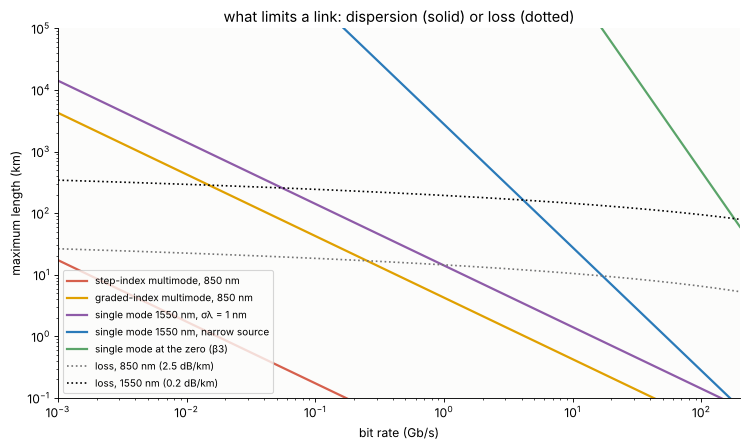

  0.1 Gb/s: single mode 1550 nm (σλ = 1 nm) 141 km, single mode 1550 nm (narrow source) 2.74e+05 km, single mode at the zero (β3) 4.67e+11 km
  1.0 Gb/s: single mode 1550 nm (σλ = 1 nm) 14.3 km, single mode 1550 nm (narrow source) 2.84e+03 km, single mode at the zero (β3) 4.92e+08 km
 10.0 Gb/s: single mode 1550 nm (σλ = 1 nm) 1.4 km, single mode 1550 nm (narrow source) 27 km, single mode at the zero (β3) 4.58e+05 km
 40.0 Gb/s: single mode 1550 nm (σλ = 1 nm) 0.349 km, single mode 1550 nm (narrow source) 1.69 km, single mode at the zero (β3) 7.12e+03 km


In [7]:
B = np.logspace(-3, 2.3, 300)              # Gb/s
h_planck = 6.62607015E-34


def loss_limit(B, wl_um, alpha_db):
    P_rec = 1000*h_planck*2.99792458E8/(wl_um*1E-6)*B*1E9*1E3       # mW
    return (0 - 10*np.log10(P_rec))/alpha_db


sig_step = 0.29*fibres.step_delay_spread(N1, N1*np.sqrt(1 - 2*Delta))        # ps per km
sig_gi = fibres.wkb_delay_spread(1.01*fibres.optimal_alpha(Delta), Delta, N1)  # ps per km
limits = [
    ("step-index multimode, 850 nm", 1E3/(4*B*sig_step), RED, "-"),
    ("graded-index multimode, 850 nm", 1E3/(4*B*sig_gi), ORANGE, "-"),
    ("single mode 1550 nm, σλ = 1 nm", 1E3/(4*B*D1550*1.0), PURPLE, "-"),
    ("single mode 1550 nm, narrow source", 1/(16*(B*1E-3)**2*abs(beta2)), BLUE, "-"),
    ("single mode at the zero (β3)", (0.324/(B*1E-3))**3/beta3, GREEN, "-"),
    ("loss, 850 nm (2.5 dB/km)", loss_limit(B, 0.85, 2.5), GREY, ":"),
    ("loss, 1550 nm (0.2 dB/km)", loss_limit(B, 1.55, 0.2), "k", ":"),
]
fig, ax = plt.subplots(figsize=(11, 6))
for name, L, c, ls in limits:
    ax.loglog(B, L, color=c, ls=ls, lw=2 if ls == "-" else 1.5, label=name)
ax.set_xlim(B[0], B[-1]); ax.set_ylim(0.1, 1E5)
ax.set_xlabel("bit rate (Gb/s)"); ax.set_ylabel("maximum length (km)")
ax.set_title("what limits a link: dispersion (solid) or loss (dotted)")
ax.legend(fontsize=9, loc="lower left")
plt.show()
for b_ in (0.1, 1.0, 10.0, 40.0):
    i = np.argmin(abs(B - b_))
    print("{:5.1f} Gb/s: ".format(b_) + ", ".join("{} {:.3g} km".format(name.split(",")[0] + (" (" + name.split(",")[1].strip() + ")" if "," in name else ""), L[i])
                                                for name, L, c, ls in limits[2:5]))

Each fibre generation is visible in the map: step-index multimode fibre for
a few Mb/s over a building, graded-index fibre for local networks (a few
Gb/s over hundreds of metres, the data centre today), and single-mode fibre
at 1550 nm, where with a narrow laser the loss limit of 100 to 300 km is
reached up to about 4 Gb/s. Above that, dispersion takes over: by this
criterion 10 Gb/s reaches about 30 km without compensation and 40 Gb/s
about 2 km. (Real NRZ links with external modulators tolerate somewhat more,
about 1000 ps/nm or 60 km at 10 Gb/s, because the receiver does not need
isolated pulses.) Optical
amplifiers remove the loss limit (spans of 80 km repeated), and then
dispersion compensation (notebook 119) or coherent receivers with digital
equalization remove the dispersion limit. Notebook 120 builds a 10 Gb/s
link with all of these numbers.

## Summary

- **Dispersion length** $L_D = T_0^2/|\beta_2|$: 18 km for a 20 ps pulse at
  1550 nm; `fibrecomm.propagate()` against the Gaussian formula and
  against `ultrafast.gaussian_broadening()`.
- **Chirp:** $C\beta_2 < 0$ compresses first; a directly modulated laser
  ($C < 0$) broadens faster at 1550 nm.
- **Third order** at the zero, $\beta_3 = 0.071$ ps³/km: asymmetric Airy
  tails, relevant for ps pulses over long fibre.
- **Source width:** a broad source spreads as $|D|L\sigma_\lambda$, checked
  with averaged noisy realizations.
- **Multimode:** impulse responses and bandwidths from the WKB delays:
  12 MHz·km (step), a few GHz·km (graded near the optimum).
- **The B–L map** collects all limits; loss limits single-mode links below
  a few Gb/s, dispersion above.

In [8]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 17 s


## References

- G. P. Agrawal, *Fiber-Optic Communication Systems*, 4th ed., Wiley
  (2010), sections 2.4 and 2.5 (pulse broadening, chirp, source width,
  bit rate limits).
- G. P. Agrawal, *Nonlinear Fiber Optics*, 5th ed., Academic Press (2013),
  chapter 3 (third-order dispersion).
- G. Keiser, *Optical Fiber Communications*, 5th ed., McGraw-Hill (2015),
  chapter 3.
- D. Marcuse, "Pulse distortion in single-mode fibers", Appl. Opt. 19,
  1653–1660 (1980).